# Taxis NYC: preparación de datos, modelos y métricas

Este cuaderno construye todo lo que usan la API y la app:

1. **Datos y serie de tiempo** de viajes por zona y hora (enero de 2024).
2. **Pronóstico con incertidumbre** (XGBoost con 9 cuantiles) comparado con la regla simple *«igual que hace una semana»*.
3. **Segmentación de zonas** con K-Means y PCA.
4. **Decisión:** cuántos taxis enviar según el costo de equivocarse.
5. **Ficha del modelo** y un **monitoreo** del error día a día.

Al final guarda los archivos que consumen `api/` y `app/`. Todas las cifras de la ficha salen de este cuaderno.

## 0. Configuración

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

URL_VIAJES = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
URL_ZONAS = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

# Reglas comunes de la actividad
MIN_VIAJES_PRONOSTICO = 3000
MIN_VIAJES_SEGMENTACION = 500
INICIO_PRUEBA = "2024-01-25"      # entrenamiento: hasta el 24 de enero, inclusive
DIA_FUTURO = "2024-02-01"         # el "mañana": no tiene datos reales
CUANTILES = [round(q, 1) for q in np.arange(0.1, 0.95, 0.1)]   # 0.1, 0.2, ..., 0.9
SEMILLA = 42

# Carpetas de salida (la estructura del repositorio)
Path("api").mkdir(exist_ok=True)
Path("app/data").mkdir(parents=True, exist_ok=True)
metricas = {}   # aquí se van guardando las cifras que usan la app y la ficha

## 1. Datos

Se descargan los viajes de taxi amarillo de enero de 2024 y el catálogo de zonas. **Viaje válido:** hora de inicio dentro de enero de 2024. **Zona de un viaje:** la de origen (`PULocationID`). Las zonas `Unknown` (264 y 265) se excluyen.

In [2]:
viajes = pd.read_parquet(URL_VIAJES)
zonas = pd.read_csv(URL_ZONAS)
print("Filas en el archivo:", len(viajes))

en_enero = (viajes["tpep_pickup_datetime"] >= "2024-01-01") & (viajes["tpep_pickup_datetime"] < "2024-02-01")
print("Viajes fuera de enero de 2024 (se descartan):", int((~en_enero).sum()))
viajes = viajes[en_enero].copy()
print("Viajes válidos:", len(viajes))

zonas_desconocidas = zonas.loc[zonas["Borough"].isna() | zonas["Borough"].eq("Unknown"), "LocationID"].tolist()
print("Zonas desconocidas que se excluyen:", zonas_desconocidas)

catalogo = zonas.set_index("LocationID").rename(columns={"Zone": "nombre", "Borough": "distrito"})[["nombre", "distrito"]]
viajes_por_zona = viajes["PULocationID"].value_counts()
viajes_por_zona = viajes_por_zona[~viajes_por_zona.index.isin(zonas_desconocidas)]

zonas_pronostico = sorted(int(z) for z in viajes_por_zona[viajes_por_zona >= MIN_VIAJES_PRONOSTICO].index)   # enteros de Python: así las categorías coinciden al guardar y cargar
zonas_segmentacion = sorted(int(z) for z in viajes_por_zona[viajes_por_zona >= MIN_VIAJES_SEGMENTACION].index)
print("Zonas que se pronostican (>= 3,000 viajes):", len(zonas_pronostico))
print("Zonas que se segmentan (>= 500 viajes):", len(zonas_segmentacion))
metricas["viajes_validos"] = int(len(viajes))
metricas["zonas_pronostico"] = len(zonas_pronostico)
metricas["zonas_segmentacion"] = len(zonas_segmentacion)

Filas en el archivo: 2964624
Viajes fuera de enero de 2024 (se descartan): 18


Viajes válidos: 2964606
Zonas desconocidas que se excluyen: [264, 265]
Zonas que se pronostican (>= 3,000 viajes): 58
Zonas que se segmentan (>= 500 viajes): 100


## 2. De viajes a una serie de tiempo

1. Se redondea la hora de inicio a la hora (`dt.floor("h")`).
2. Se cuentan los viajes por zona y hora.
3. Se **rellenan con 0** las horas sin viajes: si una hora no aparece, es porque hubo cero viajes y el modelo necesita verla.
4. Se agregan las 24 horas del 1 de febrero, vacías: son las que se van a pronosticar.

In [3]:
viajes["hora"] = viajes["tpep_pickup_datetime"].dt.floor("h")
conteo = viajes[viajes["PULocationID"].isin(zonas_pronostico)].groupby(["PULocationID", "hora"]).size()

horas = pd.date_range("2024-01-01 00:00", "2024-02-01 23:00", freq="h")
todas_zona_hora = pd.MultiIndex.from_product([zonas_pronostico, horas], names=["PULocationID", "hora"])
demanda = conteo.reindex(todas_zona_hora, fill_value=0).rename("viajes").reset_index()

# El 1 de febrero es el futuro: no hay viajes reales que mostrar
demanda.loc[demanda["hora"] >= DIA_FUTURO, "viajes"] = np.nan
print("Filas zona-hora:", len(demanda), "| zonas:", demanda["PULocationID"].nunique(), "| horas:", len(horas))
print("Horas con 0 viajes que se rellenaron:", int((demanda["viajes"] == 0).sum()))

Filas zona-hora: 44544 | zonas: 58 | horas: 768
Horas con 0 viajes que se rellenaron: 1793


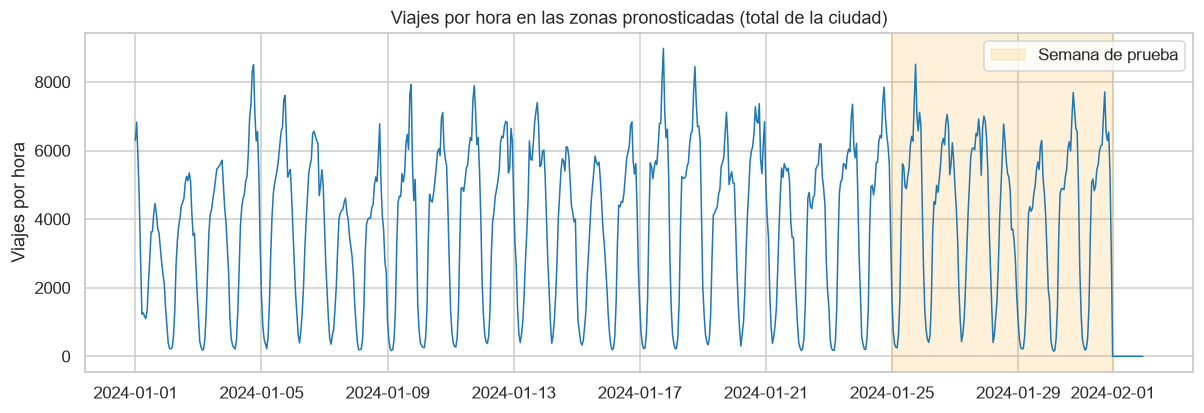

In [4]:
ciudad = demanda.groupby("hora")["viajes"].sum()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(ciudad.index, ciudad.values, lw=1, color="#1f77b4")
ax.axvspan(pd.Timestamp(INICIO_PRUEBA), pd.Timestamp("2024-02-01"), color="orange", alpha=0.15, label="Semana de prueba")
ax.set_title("Viajes por hora en las zonas pronosticadas (total de la ciudad)")
ax.set_ylabel("Viajes por hora")
ax.legend()
plt.show()

La demanda tiene un ritmo **diario** (picos de tarde, noche casi vacía) y **semanal** (los fines de semana cambian). El 15 de enero (feriado de Martin Luther King) se nota la caída. Por eso las variables más útiles serán los valores de hace 24, 48 y 168 horas.

## 3. Variables

Todas usan **solo información disponible el día anterior**: ningún lag menor a 24 horas. A las 18:00 de mañana no se conocen los viajes de las 17:00 de mañana; usar `lag_1` sería **fuga de datos**.

| Variable | Qué es |
|---|---|
| `lag_24`, `lag_48` | Viajes a la misma hora de ayer y anteayer |
| `lag_167`, `lag_168`, `lag_169` | Viajes a la misma hora de hace una semana (y la hora anterior y siguiente) |
| `media_dia_ant` | Promedio de viajes por hora del día anterior |
| `hora_dia`, `dia_semana`, `feriado` | Calendario |
| `zona` | Categoría nativa de XGBoost |

In [5]:
por_zona = demanda.groupby("PULocationID")["viajes"]       # shift por zona: los valores de una zona no se mezclan con los de otra
for k in (24, 48, 167, 168, 169):
    demanda[f"lag_{k}"] = por_zona.shift(k)

demanda["fecha"] = demanda["hora"].dt.normalize()
media_diaria = demanda.groupby(["PULocationID", "fecha"])["viajes"].mean().rename("media_dia_ant").reset_index()
media_diaria["fecha"] += pd.Timedelta(days=1)                # el promedio de AYER se asigna a HOY
demanda = demanda.merge(media_diaria, on=["PULocationID", "fecha"], how="left")

demanda["hora_dia"] = demanda["hora"].dt.hour
demanda["dia_semana"] = demanda["hora"].dt.day_of_week
demanda["feriado"] = (demanda["fecha"] == "2024-01-15").astype(int)
demanda["zona"] = pd.Categorical(demanda["PULocationID"], categories=zonas_pronostico)

VARIABLES = ["lag_24", "lag_48", "lag_167", "lag_168", "lag_169", "media_dia_ant",
             "hora_dia", "dia_semana", "feriado", "zona"]

entrenamiento = demanda[demanda["hora"] < INICIO_PRUEBA].dropna(subset=VARIABLES + ["viajes"])
prueba = demanda[(demanda["hora"] >= INICIO_PRUEBA) & (demanda["hora"] < DIA_FUTURO)]
futuro = demanda[demanda["hora"] >= DIA_FUTURO]
print("Entrenamiento:", entrenamiento["hora"].min(), "a", entrenamiento["hora"].max(), "|", len(entrenamiento), "filas")
print("Prueba:", prueba["hora"].min(), "a", prueba["hora"].max(), "|", len(prueba), "filas")
print("Futuro (1 de febrero):", len(futuro), "filas | variables faltantes:", int(futuro[VARIABLES].isna().sum().sum()))

Entrenamiento: 2024-01-08 01:00:00 a 2024-01-24 23:00:00 | 23606 filas
Prueba: 2024-01-25 00:00:00 a 2024-01-31 23:00:00 | 9744 filas
Futuro (1 de febrero): 1392 filas | variables faltantes: 0


## 4. Pronóstico con incertidumbre

**Evaluación por tiempo, nunca con `train_test_split`:** se entrena con el pasado (hasta el 24 de enero) y se prueba con la semana siguiente (25 al 31).

**Modelo:** XGBoost con `objective="reg:quantileerror"`, que entrega los 9 cuantiles (10 % a 90 %) en un solo modelo. Como el modelo puede dar cuantiles cruzados (un p60 menor que el p50), cada fila se ordena con `np.sort`.

**Regla simple de comparación:** *«igual que hace una semana»* (`lag_168`).

**Métricas:** WAPE (suma de errores absolutos / suma de viajes reales: «¿qué % de los viajes me equivoco?»), MAE (viajes por hora) y pérdida *pinball* para los cuantiles.

### 4.1 Elegir los hiperparámetros con una semana de validación
Los hiperparámetros se eligen con la **última semana del entrenamiento** (18 al 24 de enero), sin tocar la semana de prueba.

In [6]:
def pinball(real, pred, cuantiles):
    """Pérdida pinball promedio: penaliza distinto quedarse corto o pasarse según el cuantil."""
    error = np.asarray(real)[:, None] - pred
    q = np.asarray(cuantiles)
    return float(np.mean(np.maximum(q * error, (q - 1) * error)))

def wape(real, pred):
    return float(np.abs(np.asarray(real) - np.asarray(pred)).sum() / np.sum(real))

def ajustar(datos, **parametros):
    modelo = xgb.XGBRegressor(objective="reg:quantileerror", quantile_alpha=np.array(CUANTILES),
                              subsample=0.8, colsample_bytree=0.8, enable_categorical=True,
                              tree_method="hist", random_state=SEMILLA, **parametros)
    return modelo.fit(datos[VARIABLES], datos["viajes"])

def predecir(modelo, datos):
    return np.sort(modelo.predict(datos[VARIABLES]), axis=1)    # ordenar: evita cuantiles cruzados

entrena_val = entrenamiento[entrenamiento["hora"] < "2024-01-18"]
valida = entrenamiento[entrenamiento["hora"] >= "2024-01-18"]

candidatos = [dict(n_estimators=250, max_depth=5, learning_rate=0.05),
              dict(n_estimators=500, max_depth=5, learning_rate=0.10),
              dict(n_estimators=250, max_depth=4, learning_rate=0.10),
              dict(n_estimators=500, max_depth=4, learning_rate=0.05)]
filas = []
for parametros in candidatos:
    pred_val = predecir(ajustar(entrena_val, **parametros), valida)
    filas.append({**parametros, "pinball_validacion": pinball(valida["viajes"], pred_val, CUANTILES),
                  "wape_p50_validacion": wape(valida["viajes"], pred_val[:, 4]),
                  "cobertura_10_90_validacion": float(((valida["viajes"] >= pred_val[:, 0]) & (valida["viajes"] <= pred_val[:, -1])).mean())})
busqueda = pd.DataFrame(filas).round(4)
display(busqueda)
mejores_parametros = candidatos[int(busqueda["pinball_validacion"].idxmin())]
print("Hiperparámetros elegidos (menor pinball en validación):", mejores_parametros)
metricas["busqueda_hiperparametros"] = busqueda.to_dict("records")
metricas["hiperparametros"] = mejores_parametros

,n_estimators,max_depth,learning_rate,pinball_validacion,wape_p50_validacion,cobertura_10_90_validacion
0,250,5,0.05,5.8966,0.2147,0.8018
1,500,5,0.10,5.8816,0.2131,0.6875
2,250,4,0.10,5.9522,0.2174,0.7679
3,500,4,0.05,5.9410,0.2179,0.7666


Hiperparámetros elegidos (menor pinball en validación): {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.1}


### 4.2 Modelo final y evaluación en la semana de prueba (25 al 31 de enero)

In [7]:
modelo = ajustar(entrenamiento, **mejores_parametros)
pred = predecir(modelo, prueba)
real = prueba["viajes"].to_numpy()
semana = prueba["lag_168"].to_numpy()      # regla simple: igual que hace una semana
ayer = prueba["lag_24"].to_numpy()         # regla simple 2: igual que ayer

dentro_10_90 = (real >= pred[:, 0]) & (real <= pred[:, -1])
tabla = pd.DataFrame({
    "WAPE": [wape(real, pred[:, 4]), wape(real, semana), wape(real, ayer)],
    "MAE (viajes por hora)": [np.abs(real - pred[:, 4]).mean(), np.abs(real - semana).mean(), np.abs(real - ayer).mean()],
}, index=["Modelo (mediana p50)", "Igual que hace una semana", "Igual que ayer"]).round(4)
display(tabla)
print("Pinball del modelo (9 cuantiles):", round(pinball(real, pred, CUANTILES), 3))
print("Cobertura del rango 10%-90% (debería ser cerca de 80%):", round(float(dentro_10_90.mean()), 3))
cobertura_por_cuantil = {f"p{int(q * 100)}": float((real <= pred[:, i]).mean()) for i, q in enumerate(CUANTILES)}
print("Cobertura de cada cuantil (debería ser ≈ su nivel):", {k: round(v, 2) for k, v in cobertura_por_cuantil.items()})

metricas["prueba"] = {
    "wape_modelo": wape(real, pred[:, 4]), "wape_semana": wape(real, semana), "wape_ayer": wape(real, ayer),
    "mae_modelo": float(np.abs(real - pred[:, 4]).mean()), "mae_semana": float(np.abs(real - semana).mean()),
    "mae_ayer": float(np.abs(real - ayer).mean()),
    "pinball": pinball(real, pred, CUANTILES), "cobertura_80": float(dentro_10_90.mean()),
    "cobertura_por_cuantil": cobertura_por_cuantil, "filas": int(len(real)),
}

,WAPE,MAE (viajes por hora)
Modelo (mediana p50),0.1639,11.6102
Igual que hace una semana,0.1678,11.8818
Igual que ayer,0.3006,21.2863


Pinball del modelo (9 cuantiles): 4.535
Cobertura del rango 10%-90% (debería ser cerca de 80%): 0.808
Cobertura de cada cuantil (debería ser ≈ su nivel): {'p10': 0.1, 'p20': 0.21, 'p30': 0.31, 'p40': 0.42, 'p50': 0.52, 'p60': 0.62, 'p70': 0.72, 'p80': 0.82, 'p90': 0.91}


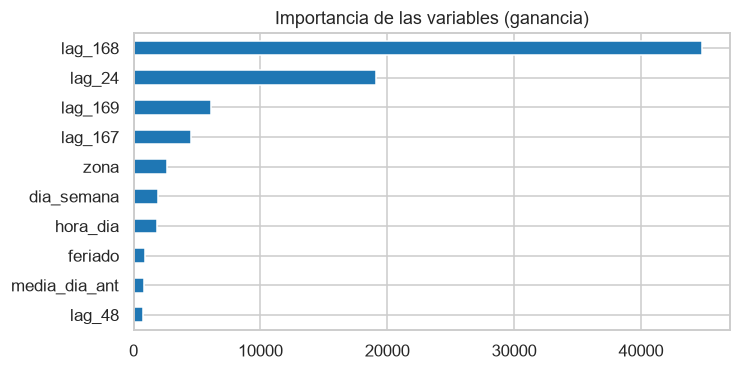

In [8]:
importancia = pd.Series(modelo.get_booster().get_score(importance_type="gain")).sort_values()
importancia.plot(kind="barh", figsize=(7, 3.5), color="#1f77b4", title="Importancia de las variables (ganancia)")
plt.show()
metricas["importancia_variables"] = (importancia / importancia.sum()).sort_values(ascending=False).round(4).to_dict()

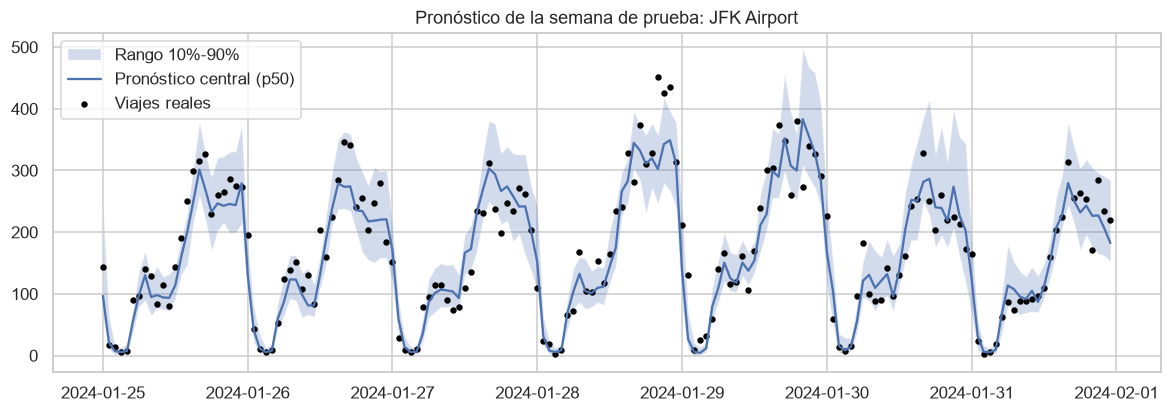

In [9]:
# Un día de la semana de prueba en la zona con más viajes
zona_ejemplo = int(viajes_por_zona.index[0])
comparacion = prueba.assign(p10=pred[:, 0], p50=pred[:, 4], p90=pred[:, -1]).query("PULocationID == @zona_ejemplo")
fig, ax = plt.subplots(figsize=(13, 4))
ax.fill_between(comparacion["hora"], comparacion["p10"], comparacion["p90"], alpha=0.25, label="Rango 10%-90%")
ax.plot(comparacion["hora"], comparacion["p50"], label="Pronóstico central (p50)")
ax.scatter(comparacion["hora"], comparacion["viajes"], s=10, color="black", label="Viajes reales")
ax.set_title(f"Pronóstico de la semana de prueba: {catalogo.loc[zona_ejemplo, 'nombre']}")
ax.legend()
plt.show()

### 4.3 Monitoreo: error día a día de la semana de prueba

El **límite de alerta** se define con la semana de validación (la última semana del entrenamiento): **1.25 veces** su error diario promedio. Si un día de la semana de prueba lo supera, la app avisa.

,viajes_reales,wape_modelo,wape_semana,supera_limite
fecha,,,,
2024-01-25,107641.0,0.1338,0.1490,False
2024-01-26,103023.0,0.1470,0.1701,False
2024-01-27,108142.0,0.1848,0.1982,False
2024-01-28,90342.0,0.2135,0.2090,False
2024-01-29,82177.0,0.2073,0.1485,False
2024-01-30,98993.0,0.1388,0.1519,False
2024-01-31,99719.0,0.1358,0.1470,False


Límite de alerta (1.25 × error diario promedio de validación): 0.2759


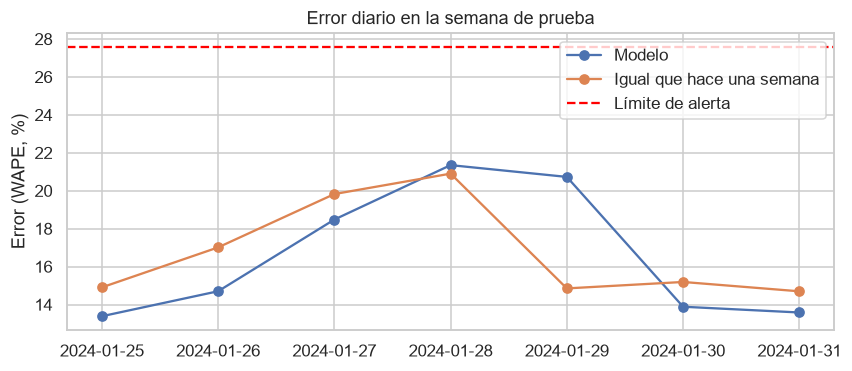

In [10]:
pred_val_final = predecir(ajustar(entrena_val, **mejores_parametros), valida)
error_val = (valida.assign(error=np.abs(valida["viajes"] - pred_val_final[:, 4])).groupby("fecha")
             .apply(lambda d: d["error"].sum() / d["viajes"].sum(), include_groups=False))
limite_wape = float(1.25 * error_val.mean())

prueba = prueba.assign(p50=pred[:, 4], error_abs=np.abs(real - pred[:, 4]), error_semana=np.abs(real - semana))
por_dia = (prueba.groupby("fecha")
           .apply(lambda d: pd.Series({"viajes_reales": d["viajes"].sum(),
                                       "wape_modelo": d["error_abs"].sum() / d["viajes"].sum(),
                                       "wape_semana": d["error_semana"].sum() / d["viajes"].sum()}), include_groups=False))
por_dia["supera_limite"] = por_dia["wape_modelo"] > limite_wape
display(por_dia.round(4))
print("Límite de alerta (1.25 × error diario promedio de validación):", round(limite_wape, 4))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(por_dia.index, por_dia["wape_modelo"] * 100, marker="o", label="Modelo")
ax.plot(por_dia.index, por_dia["wape_semana"] * 100, marker="o", label="Igual que hace una semana")
ax.axhline(limite_wape * 100, color="red", linestyle="--", label="Límite de alerta")
ax.set_ylabel("Error (WAPE, %)")
ax.set_title("Error diario en la semana de prueba")
ax.legend()
plt.show()

metricas["error_diario"] = [{"fecha": f.strftime("%Y-%m-%d"), **{k: (bool(v) if k == "supera_limite" else float(v)) for k, v in fila.items()}}
                            for f, fila in por_dia.iterrows()]
metricas["limite_wape"] = limite_wape

error_diario_zona = (prueba.groupby(["PULocationID", "fecha"])
                     .apply(lambda d: pd.Series({"viajes_reales": d["viajes"].sum(), "wape_modelo": d["error_abs"].sum() / max(d["viajes"].sum(), 1)}),
                            include_groups=False).reset_index())
error_diario_zona["fecha"] = error_diario_zona["fecha"].dt.strftime("%Y-%m-%d")
error_diario_zona.round(4).to_csv("app/data/error_diario_zona.csv", index=False)

## 5. Segmentación de zonas (K-Means + PCA)

Una fila por zona con **cómo se usa**: viajes por día (en escala logarítmica, porque hay zonas con 30 y otras con 4,500), distancia, tarifa y propina medianas (sin viajes con distancia o tarifa ≤ 0) y el porcentaje de viajes en fin de semana y en tres franjas horarias. Las variables se **escalan** antes de K-Means.

In [11]:
viajes_seg = viajes[viajes["PULocationID"].isin(zonas_segmentacion)].copy()
viajes_seg["es_finde"] = viajes_seg["tpep_pickup_datetime"].dt.day_of_week >= 5
hora = viajes_seg["tpep_pickup_datetime"].dt.hour
viajes_seg["franja_6_10"] = hora.between(6, 10)
viajes_seg["franja_16_20"] = hora.between(16, 20)
viajes_seg["franja_22_5"] = (hora >= 22) | (hora <= 5)
validos = viajes_seg[(viajes_seg["trip_distance"] > 0) & (viajes_seg["fare_amount"] > 0)]

perfil = pd.DataFrame({"viajes_dia": viajes_seg.groupby("PULocationID").size() / 31})
perfil["log_viajes_dia"] = np.log10(perfil["viajes_dia"])
perfil["dist_mediana"] = validos.groupby("PULocationID")["trip_distance"].median()
perfil["tarifa_mediana"] = validos.groupby("PULocationID")["fare_amount"].median()
perfil["propina_mediana"] = validos.groupby("PULocationID")["tip_amount"].median()
perfil["pct_finde"] = viajes_seg.groupby("PULocationID")["es_finde"].mean()
perfil["pct_6_10"] = viajes_seg.groupby("PULocationID")["franja_6_10"].mean()
perfil["pct_16_20"] = viajes_seg.groupby("PULocationID")["franja_16_20"].mean()
perfil["pct_22_5"] = viajes_seg.groupby("PULocationID")["franja_22_5"].mean()

VARIABLES_SEG = ["log_viajes_dia", "dist_mediana", "tarifa_mediana", "propina_mediana",
                 "pct_finde", "pct_6_10", "pct_16_20", "pct_22_5"]
print("Zonas sin viajes válidos para distancia o tarifa (se rellenan con la mediana):", int(perfil[VARIABLES_SEG].isna().any(axis=1).sum()))
X = StandardScaler().fit_transform(perfil[VARIABLES_SEG].fillna(perfil[VARIABLES_SEG].median()))
display(perfil[VARIABLES_SEG].describe().round(2))

Zonas sin viajes válidos para distancia o tarifa (se rellenan con la mediana): 0


,log_viajes_dia,dist_mediana,tarifa_mediana,propina_mediana,pct_finde,pct_6_10,pct_16_20,pct_22_5
count,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
mean,2.36,3.43,20.11,1.97,0.26,0.22,0.26,0.20
std,0.86,2.78,11.99,2.06,0.09,0.11,0.08,0.13
min,1.21,1.23,10.00,0.00,0.10,0.05,0.07,0.02
25%,1.48,1.61,12.10,0.00,0.21,0.14,0.21,0.12
50%,2.35,2.44,17.00,2.44,0.25,0.21,0.28,0.17
75%,3.20,4.08,24.50,2.80,0.30,0.28,0.33,0.23
max,3.67,17.45,70.00,10.05,0.55,0.58,0.43,0.72


### 5.1 ¿Cuántos grupos? Coeficiente de silueta para k = 2 a 7

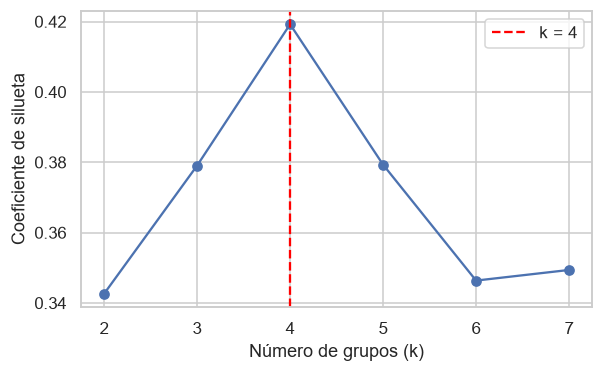

{2: 0.343, 3: 0.379, 4: 0.419, 5: 0.379, 6: 0.346, 7: 0.349} -> k elegido: 4


In [12]:
siluetas = {k: float(silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit_predict(X))) for k in range(2, 8)}
k_elegido = max(siluetas, key=siluetas.get)
plt.figure(figsize=(6, 3.5))
plt.plot(list(siluetas), list(siluetas.values()), marker="o")
plt.axvline(k_elegido, color="red", linestyle="--", label=f"k = {k_elegido}")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Coeficiente de silueta")
plt.legend()
plt.show()
print({k: round(v, 3) for k, v in siluetas.items()}, "-> k elegido:", k_elegido)
metricas["siluetas"] = {str(k): v for k, v in siluetas.items()}
metricas["k_elegido"] = k_elegido

### 5.2 Grupos con nombre según su perfil
K-Means numera los grupos al azar, así que **no se nombran a mano por número**: cada grupo se nombra por lo que lo distingue (el de mayor distancia mediana son los aeropuertos, etc.).

In [13]:
kmeans = KMeans(n_clusters=k_elegido, n_init=10, random_state=SEMILLA).fit(X)
perfil["grupo"] = kmeans.labels_
medianas = perfil.groupby("grupo")[VARIABLES_SEG + ["viajes_dia"]].median()

def nombrar_grupos(medianas):
    """Nombra cada grupo según su perfil, sin depender del número que le tocó."""
    nombres, restantes = {}, list(medianas.index)
    reglas = [("dist_mediana", "Aeropuertos y viajes largos"),
              ("viajes_dia", "Centro de alta demanda"),
              ("pct_22_5", "Vida nocturna y fin de semana")]
    for variable, nombre in reglas:
        if restantes:
            ganador = medianas.loc[restantes, variable].idxmax()
            nombres[ganador] = nombre
            restantes.remove(ganador)
    for g in restantes:
        nombres[g] = "Barrios residenciales de baja demanda"
    return nombres

nombres_grupos = nombrar_grupos(medianas)
perfil["grupo_nombre"] = perfil["grupo"].map(nombres_grupos)
resumen_grupos = (perfil.groupby("grupo_nombre")
                  .agg(zonas=("viajes_dia", "size"), viajes_dia=("viajes_dia", "median"), dist_mediana=("dist_mediana", "median"),
                       tarifa_mediana=("tarifa_mediana", "median"), propina_mediana=("propina_mediana", "median"),
                       pct_finde=("pct_finde", "median"), pct_noche=("pct_22_5", "median"))
                  .round(2))
display(resumen_grupos)
for nombre in resumen_grupos.index:
    ejemplos = catalogo.loc[perfil.index[perfil["grupo_nombre"] == nombre], "nombre"].head(6).tolist()
    print(f"{nombre}: {', '.join(ejemplos)}")

,zonas,viajes_dia,dist_mediana,tarifa_mediana,propina_mediana,pct_finde,pct_noche
grupo_nombre,,,,,,,
Aeropuertos y viajes largos,5,396.29,9.49,70.0,10.00,0.23,0.18
Barrios residenciales de baja demanda,37,29.45,3.83,24.5,0.00,0.23,0.19
Centro de alta demanda,46,1525.63,1.60,12.1,2.66,0.25,0.14
Vida nocturna y fin de semana,12,442.89,2.09,14.2,2.57,0.42,0.52


Aeropuertos y viajes largos: Baisley Park, East Elmhurst, Flushing Meadows-Corona Park, JFK Airport, LaGuardia Airport
Barrios residenciales de baja demanda: Astoria, Bedford, Boerum Hill, Brooklyn Heights, Brownsville, Bushwick South
Centro de alta demanda: Battery Park, Battery Park City, Bloomingdale, Central Harlem, Central Park, Chinatown
Vida nocturna y fin de semana: Alphabet City, East Village, East Williamsburg, Greenpoint, Greenwich Village South, Little Italy/NoLiTa


### 5.3 PCA a dos componentes para dibujar las zonas

Variación conservada por cada componente: [0.379 0.27 ] | total: 0.648


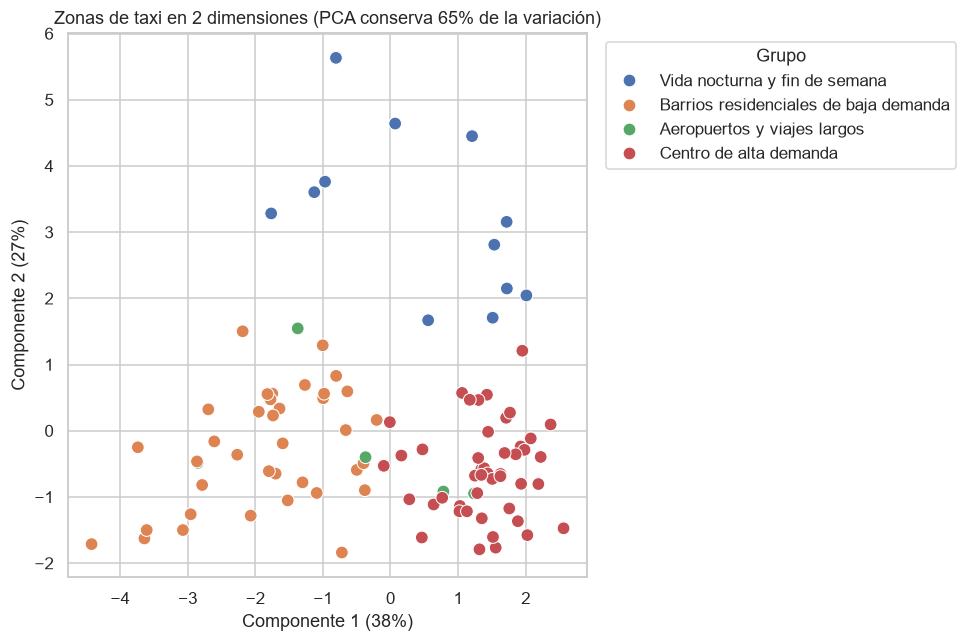

In [14]:
pca = PCA(n_components=2, random_state=SEMILLA).fit(X)
componentes = pca.transform(X)
perfil["pca1"], perfil["pca2"] = componentes[:, 0], componentes[:, 1]
varianza = pca.explained_variance_ratio_
print("Variación conservada por cada componente:", varianza.round(3), "| total:", round(float(varianza.sum()), 3))

plt.figure(figsize=(9, 6))
sns.scatterplot(data=perfil, x="pca1", y="pca2", hue="grupo_nombre", s=70)
plt.title(f"Zonas de taxi en 2 dimensiones (PCA conserva {varianza.sum():.0%} de la variación)")
plt.xlabel(f"Componente 1 ({varianza[0]:.0%})")
plt.ylabel(f"Componente 2 ({varianza[1]:.0%})")
plt.legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
metricas["pca_varianza"] = [float(v) for v in varianza]

In [15]:
# Perfil horario (proporción de viajes en cada hora) para la mini-gráfica de la app
horario = (viajes_seg.assign(h=hora).groupby(["PULocationID", "h"]).size().unstack(fill_value=0))
horario = horario.reindex(columns=range(24), fill_value=0)
horario = horario.div(horario.sum(axis=1), axis=0).round(4)

zonas_segmentadas = (perfil.reset_index().rename(columns={"PULocationID": "zona_id"})
                     .merge(catalogo, left_on="zona_id", right_index=True))
zonas_segmentadas["perfil_24h"] = zonas_segmentadas["zona_id"].map(lambda z: ";".join(str(v) for v in horario.loc[z]))
zonas_segmentadas["se_pronostica"] = zonas_segmentadas["zona_id"].isin(zonas_pronostico)
zonas_segmentadas = zonas_segmentadas.round(4)
zonas_segmentadas.to_csv("app/data/zonas_segmentadas.csv", index=False)

descripciones = {
    "Aeropuertos y viajes largos": "Pocas zonas con los viajes más largos y más caros y las propinas más altas: el servicio de y hacia los aeropuertos.",
    "Centro de alta demanda": "Las zonas con más viajes por día, de distancia corta y tarifa baja: el corazón de Manhattan.",
    "Vida nocturna y fin de semana": "Barrios con una demanda alta y con la mayor parte de sus viajes de noche (22 a 5 h) y en fin de semana.",
    "Barrios residenciales de baja demanda": "Pocos viajes por día (unas decenas), viajes más largos que en el centro, propina mediana de cero y más viajes de mañana (6 a 10 h): demanda dispersa y difícil de pronosticar.",
}
metricas["grupos"] = [{"nombre": n, "descripcion": descripciones.get(n, ""), **fila.to_dict()} for n, fila in resumen_grupos.iterrows()]
print("Guardado: app/data/zonas_segmentadas.csv con", len(zonas_segmentadas), "zonas")

Guardado: app/data/zonas_segmentadas.csv con 100 zonas


## 6. Dónde se equivoca más el modelo (unión de las Partes 1 y 2)

In [16]:
tipo_de_zona = perfil["grupo_nombre"].rename("grupo_nombre")
por_tipo = (prueba.assign(p10=pred[:, 0], p90=pred[:, -1]).join(tipo_de_zona, on="PULocationID")
            .groupby("grupo_nombre")
            .apply(lambda d: pd.Series({
                "zonas": d["PULocationID"].nunique(),
                "viajes_por_hora_promedio": d["viajes"].mean(),
                "wape_modelo": d["error_abs"].sum() / d["viajes"].sum(),
                "wape_semana": d["error_semana"].sum() / d["viajes"].sum(),
                "cobertura_80": ((d["viajes"] >= d["p10"]) & (d["viajes"] <= d["p90"])).mean()}), include_groups=False)
            .round(3))
display(por_tipo)
metricas["por_tipo_de_zona"] = por_tipo.reset_index().to_dict("records")

por_zona_error = (prueba.groupby("PULocationID")
                  .apply(lambda d: pd.Series({"viajes_por_hora": d["viajes"].mean(), "wape": d["error_abs"].sum() / d["viajes"].sum()}), include_groups=False)
                  .join(catalogo))
peores = por_zona_error.sort_values("wape", ascending=False).head(5)
display(peores.round(3))
metricas["zonas_con_mas_error"] = [{"zona": r["nombre"], "viajes_por_hora": float(r["viajes_por_hora"]), "wape": float(r["wape"])} for _, r in peores.iterrows()]
metricas["zonas_con_menos_de_3000_viajes"] = int((viajes_por_zona < MIN_VIAJES_PRONOSTICO).sum())
metricas["zonas_sin_pronostico_pero_segmentadas"] = int(len(zonas_segmentacion) - len(zonas_pronostico))

,zonas,viajes_por_hora_promedio,wape_modelo,wape_semana,cobertura_80
grupo_nombre,,,,,
Aeropuertos y viajes largos,3.0,100.996,0.178,0.199,0.815
Barrios residenciales de baja demanda,3.0,5.970,0.382,0.477,0.851
Centro de alta demanda,44.0,77.243,0.159,0.161,0.802
Vida nocturna y fin de semana,8.0,48.471,0.185,0.187,0.824


,viajes_por_hora,wape,nombre,distrito
PULocationID,,,,
232,4.577,0.485,Two Bridges/Seward Park,Manhattan
42,4.048,0.465,Central Harlem North,Manhattan
4,6.345,0.462,Alphabet City,Manhattan
209,6.452,0.413,Seaport,Manhattan
45,5.244,0.412,Chinatown,Manhattan


## 7. Decisión: cuántos taxis enviar

Si quedarse corto cuesta más que pasarse, conviene enviar más que el pronóstico central. El **cuantil óptimo** es:

$$\text{cuantil óptimo} = \frac{C_p}{C_p + C_o}$$

con $C_p$ = costo de un pasajero perdido y $C_o$ = costo de un taxi ocioso (una hora sin pasajero). Con 40 y 10 dólares da 0.80. Se simplifica suponiendo que **un taxi atiende un viaje por hora**.

In [17]:
def cuantil_optimo(costo_perdido, costo_ocioso):
    return costo_perdido / (costo_perdido + costo_ocioso)

def taxis_a_enviar(pred, nivel):
    """Interpola entre p10 y p90 el cuantil `nivel` y redondea hacia arriba (un taxi = un viaje por hora)."""
    nivel = float(np.clip(nivel, CUANTILES[0], CUANTILES[-1]))
    return np.ceil(np.array([np.interp(nivel, CUANTILES, fila) for fila in pred]))

def costo_total(enviados, real, costo_ocioso, costo_perdido):
    ociosos = np.maximum(enviados - real, 0)
    perdidos = np.maximum(real - enviados, 0)
    return float((ociosos * costo_ocioso + perdidos * costo_perdido).sum())

COSTO_OCIOSO, COSTO_PERDIDO = 10, 40
nivel = cuantil_optimo(COSTO_PERDIDO, COSTO_OCIOSO)
recomendado = taxis_a_enviar(pred, nivel)
costos = {"Recomendación (cuantil óptimo)": costo_total(recomendado, real, COSTO_OCIOSO, COSTO_PERDIDO),
          "Enviar el pronóstico central (p50)": costo_total(np.ceil(pred[:, 4]), real, COSTO_OCIOSO, COSTO_PERDIDO),
          "Igual que hace una semana": costo_total(semana, real, COSTO_OCIOSO, COSTO_PERDIDO)}
tabla_costos = pd.Series(costos, name="costo en USD").round(0)
display(tabla_costos.to_frame())
ahorro_p50 = 1 - costos["Recomendación (cuantil óptimo)"] / costos["Enviar el pronóstico central (p50)"]
ahorro_semana = 1 - costos["Recomendación (cuantil óptimo)"] / costos["Igual que hace una semana"]
print(f"Cuantil óptimo: {nivel:.2f} | ahorro frente al p50: {ahorro_p50:.1%} | frente a hace una semana: {ahorro_semana:.1%}")
metricas["decision_ejemplo"] = {"costo_ocioso": COSTO_OCIOSO, "costo_perdido": COSTO_PERDIDO, "cuantil": nivel,
                                "costo_recomendado": costos["Recomendación (cuantil óptimo)"],
                                "costo_p50": costos["Enviar el pronóstico central (p50)"],
                                "costo_semana": costos["Igual que hace una semana"],
                                "ahorro_frente_p50": ahorro_p50, "ahorro_frente_semana": ahorro_semana}

,costo en USD
Recomendación (cuantil óptimo),2219390.0
Enviar el pronóstico central (p50),2831730.0
Igual que hace una semana,3160950.0


Cuantil óptimo: 0.80 | ahorro frente al p50: 21.6% | frente a hace una semana: 29.8%


## 8. Guardar para la API y la app

- `api/modelo_pronostico.ubj`: el modelo (formato binario de XGBoost).
- `api/demanda.parquet`: las horas del 25 de enero al 1 de febrero **con sus variables ya calculadas**; la API solo busca y predice.
- `app/data/…`: zonas segmentadas, métricas y error diario.

In [18]:
modelo.save_model("api/modelo_pronostico.ubj")

api_demanda = demanda[demanda["hora"] >= INICIO_PRUEBA].copy()
api_demanda = api_demanda.join(catalogo, on="PULocationID").rename(columns={"nombre": "zona_nombre"})
columnas_api = ["PULocationID", "zona_nombre", "distrito", "hora", "viajes"] + VARIABLES
api_demanda = api_demanda[columnas_api].reset_index(drop=True)
api_demanda["PULocationID"] = api_demanda["PULocationID"].astype("int32")
api_demanda.to_parquet("api/demanda.parquet", index=False)

# Comprobación: la API carga el modelo con xgboost.Booster (no necesita scikit-learn) y, como el parquet
# puede devolver la zona como número, la vuelve a convertir en categoría con las mismas categorías.
recargado = xgb.Booster()
recargado.load_model("api/modelo_pronostico.ubj")
comprobacion = pd.read_parquet("api/demanda.parquet")
comprobacion["zona"] = pd.Categorical(comprobacion["PULocationID"], categories=sorted(int(z) for z in comprobacion["PULocationID"].unique()))   # enteros de Python: el tipo debe coincidir con el del entrenamiento
prueba_api = comprobacion[comprobacion["hora"] < DIA_FUTURO]
pred_api = np.sort(recargado.predict(xgb.DMatrix(prueba_api[VARIABLES], enable_categorical=True)), axis=1)
assert np.allclose(pred_api, pred, atol=1e-4)
print("API: filas en demanda.parquet:", len(comprobacion), "| el modelo recargado da las mismas predicciones")

peso_mb = Path("api/modelo_pronostico.ubj").stat().st_size / 1e6
print(f"Tamaño del modelo: {peso_mb:.1f} MB")
metricas["modelo_mb"] = round(peso_mb, 1)

API: filas en demanda.parquet: 11136 | el modelo recargado da las mismas predicciones
Tamaño del modelo: 15.8 MB


## 9. Ficha del modelo (model card)

In [19]:
p = metricas["prueba"]
d = metricas["decision_ejemplo"]
peor_dia = max(metricas["error_diario"], key=lambda f: f["wape_modelo"])
dias_alerta = [f["fecha"] for f in metricas["error_diario"] if f["supera_limite"]]
tipo_peor = max(metricas["por_tipo_de_zona"], key=lambda f: f["wape_modelo"])
tipo_mejor = min(metricas["por_tipo_de_zona"], key=lambda f: f["wape_modelo"])
gana = p["wape_modelo"] < p["wape_semana"]
dias_gana = sum(f["wape_modelo"] < f["wape_semana"] for f in metricas["error_diario"])

ficha = f"""# Ficha del modelo: pronóstico de viajes de taxi por zona y hora

## Para qué sirve
Pronostica cuántos viajes de taxi amarillo habrá **por hora y por zona** de Nueva York el día siguiente, con un rango de incertidumbre (cuantiles de 10 % a 90 %), para decidir cuántos taxis enviar a cada zona.

## Con qué datos se entrenó
Viajes de taxi amarillo de enero de 2024 (NYC TLC): {metricas["viajes_validos"]:,} viajes válidos. Se pronostican {metricas["zonas_pronostico"]} zonas con al menos 3,000 viajes en el mes. Entrenamiento: del 8 al 24 de enero (la primera semana solo sirve para calcular los valores pasados de cada hora). Prueba: del 25 al 31 de enero.

## Cómo se evaluó
Por tiempo, nunca al azar: se entrena con el pasado y se prueba con la semana siguiente. Variables: valores de hace 24, 48 y 168 horas (nunca menos de 24: así no hay fuga de datos), promedio del día anterior, hora, día de la semana, feriado y zona. Modelo: XGBoost con 9 cuantiles; hiperparámetros elegidos con la semana de validación (18 al 24 de enero): {metricas["hiperparametros"]}.

## Qué tan bien funciona
| | Error (WAPE) | Error (viajes por hora) |
|---|---|---|
| Modelo (mediana) | {p["wape_modelo"]:.1%} | {p["mae_modelo"]:.1f} |
| Igual que hace una semana | {p["wape_semana"]:.1%} | {p["mae_semana"]:.1f} |
| Igual que ayer | {p["wape_ayer"]:.1%} | {p["mae_ayer"]:.1f} |

{"El modelo le gana a" if gana else "El modelo **no** le gana a"} «igual que hace una semana» {"por " + format(abs(p["wape_semana"] - p["wape_modelo"]) * 100, ".1f") + " puntos porcentuales: una ventaja pequeña" if gana else "(pierde por " + format(abs(p["wape_semana"] - p["wape_modelo"]) * 100, ".1f") + " puntos porcentuales)"}. Por día, gana en {dias_gana} de {len(metricas["error_diario"])} días de la semana de prueba. **Su valor está en el rango de incertidumbre**, que la regla simple no da: el rango del 80 % (de p10 a p90) cubre el **{p["cobertura_80"]:.1%}** de las horas reales, cuando debería cubrir cerca del 80 %.

Con costos de USD {d["costo_perdido"]} por pasajero perdido y USD {d["costo_ocioso"]} por taxi ocioso (cuantil óptimo {d["cuantil"]:.2f}), enviar el cuantil recomendado cuesta USD {d["costo_recomendado"]:,.0f} en la semana de prueba, contra USD {d["costo_p50"]:,.0f} del pronóstico central ({d["ahorro_frente_p50"]:.0%} menos) y USD {d["costo_semana"]:,.0f} de «igual que hace una semana» ({d["ahorro_frente_semana"]:.0%} menos).

## Dónde se equivoca más
- Por tipo de zona, el error es mayor en **«{tipo_peor["grupo_nombre"]}»** ({tipo_peor["wape_modelo"]:.1%}, solo {int(tipo_peor["zonas"])} zonas pronosticadas, con unos {tipo_peor["viajes_por_hora_promedio"]:.0f} viajes por hora: con pocos viajes el ruido pesa más) y menor en **«{tipo_mejor["grupo_nombre"]}»** ({tipo_mejor["wape_modelo"]:.1%}, {int(tipo_mejor["zonas"])} zonas).
- Por día, el peor fue el **{peor_dia["fecha"]}** ({peor_dia["wape_modelo"]:.1%}). Días sobre el límite de alerta ({metricas["limite_wape"]:.1%}): {", ".join(dias_alerta) if dias_alerta else "ninguno"}.

## Limitaciones y usos no recomendados
- Solo hay **un mes** de datos: no ve estacionalidad anual, clima, eventos ni obras. Un evento fuera de lo normal (nevada, concierto, huelga) no está en el modelo.
- Solo cubre **taxis amarillos** y las **{metricas["zonas_pronostico"]} zonas** con al menos 3,000 viajes; hay {metricas["zonas_sin_pronostico_pero_segmentadas"]} zonas más (con 500 a 2,999 viajes) que se segmentan pero **no se pronostican**, y en total {metricas["zonas_con_menos_de_3000_viajes"]} zonas con viajes quedan sin pronóstico.
- Se supone que un taxi atiende un viaje por hora; en la realidad un viaje dura más o menos de una hora.
- El pronóstico mide **viajes que se realizaron**, no la demanda real: donde faltan taxis, la demanda no atendida no aparece en los datos.
- **No usar** para recortar el servicio en barrios con pocos viajes de taxi amarillo: el modelo puede subestimar la demanda de zonas con transporte público deficiente o donde la gente usa otros servicios, y quienes viven ahí (a menudo con menos alternativas) serían los perjudicados. Tampoco para evaluar a conductores ni para decisiones de precios.
"""
Path("ficha_modelo.md").write_text(ficha, encoding="utf-8")
metricas["ficha_md"] = ficha
display(Markdown(ficha))

# Ficha del modelo: pronóstico de viajes de taxi por zona y hora

## Para qué sirve
Pronostica cuántos viajes de taxi amarillo habrá **por hora y por zona** de Nueva York el día siguiente, con un rango de incertidumbre (cuantiles de 10 % a 90 %), para decidir cuántos taxis enviar a cada zona.

## Con qué datos se entrenó
Viajes de taxi amarillo de enero de 2024 (NYC TLC): 2,964,606 viajes válidos. Se pronostican 58 zonas con al menos 3,000 viajes en el mes. Entrenamiento: del 8 al 24 de enero (la primera semana solo sirve para calcular los valores pasados de cada hora). Prueba: del 25 al 31 de enero.

## Cómo se evaluó
Por tiempo, nunca al azar: se entrena con el pasado y se prueba con la semana siguiente. Variables: valores de hace 24, 48 y 168 horas (nunca menos de 24: así no hay fuga de datos), promedio del día anterior, hora, día de la semana, feriado y zona. Modelo: XGBoost con 9 cuantiles; hiperparámetros elegidos con la semana de validación (18 al 24 de enero): {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.1}.

## Qué tan bien funciona
| | Error (WAPE) | Error (viajes por hora) |
|---|---|---|
| Modelo (mediana) | 16.4% | 11.6 |
| Igual que hace una semana | 16.8% | 11.9 |
| Igual que ayer | 30.1% | 21.3 |

El modelo le gana a «igual que hace una semana» por 0.4 puntos porcentuales: una ventaja pequeña. Por día, gana en 5 de 7 días de la semana de prueba. **Su valor está en el rango de incertidumbre**, que la regla simple no da: el rango del 80 % (de p10 a p90) cubre el **80.8%** de las horas reales, cuando debería cubrir cerca del 80 %.

Con costos de USD 40 por pasajero perdido y USD 10 por taxi ocioso (cuantil óptimo 0.80), enviar el cuantil recomendado cuesta USD 2,219,390 en la semana de prueba, contra USD 2,831,730 del pronóstico central (22% menos) y USD 3,160,950 de «igual que hace una semana» (30% menos).

## Dónde se equivoca más
- Por tipo de zona, el error es mayor en **«Barrios residenciales de baja demanda»** (38.2%, solo 3 zonas pronosticadas, con unos 6 viajes por hora: con pocos viajes el ruido pesa más) y menor en **«Centro de alta demanda»** (15.9%, 44 zonas).
- Por día, el peor fue el **2024-01-28** (21.3%). Días sobre el límite de alerta (27.6%): ninguno.

## Limitaciones y usos no recomendados
- Solo hay **un mes** de datos: no ve estacionalidad anual, clima, eventos ni obras. Un evento fuera de lo normal (nevada, concierto, huelga) no está en el modelo.
- Solo cubre **taxis amarillos** y las **58 zonas** con al menos 3,000 viajes; hay 42 zonas más (con 500 a 2,999 viajes) que se segmentan pero **no se pronostican**, y en total 200 zonas con viajes quedan sin pronóstico.
- Se supone que un taxi atiende un viaje por hora; en la realidad un viaje dura más o menos de una hora.
- El pronóstico mide **viajes que se realizaron**, no la demanda real: donde faltan taxis, la demanda no atendida no aparece en los datos.
- **No usar** para recortar el servicio en barrios con pocos viajes de taxi amarillo: el modelo puede subestimar la demanda de zonas con transporte público deficiente o donde la gente usa otros servicios, y quienes viven ahí (a menudo con menos alternativas) serían los perjudicados. Tampoco para evaluar a conductores ni para decisiones de precios.


In [20]:
Path("app/data/metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
print("Guardado: app/data/metricas.json")

Guardado: app/data/metricas.json


## 10. Conclusiones

1. **El modelo casi empata con «igual que hace una semana»** en el error del pronóstico central: la demanda de taxis se repite mucho de una semana a otra. Lo que sí aporta es el **rango de incertidumbre**, que permite decidir cuántos taxis enviar según el costo de equivocarse.
2. **El cuantil óptimo** convierte ese rango en una decisión: con costos de USD 40 y USD 10 se envía el cuantil 0.80 y el costo baja frente a las dos reglas simples (ver la sección 7).
3. **Las zonas se agrupan en pocos tipos** de uso (aeropuertos, centro, vida nocturna y barrios residenciales) y el error del pronóstico cambia por tipo de zona (sección 6).
4. **Límites:** un solo mes de datos, solo taxis amarillos y solo zonas con al menos 3,000 viajes. No debe usarse para recortar servicio en barrios con pocos viajes.